# Telco Customer Churn — Classification

Goal: predict whether a customer will leave the company (`Churn Value = 1`) and find the factors that drive churn.

## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns

## 2. Load the Data

In [2]:
import glob
kaggle_files = glob.glob('/kaggle/input/**/Telco_customer_churn.csv', recursive=True)
if kaggle_files:
    tele = pd.read_csv(kaggle_files[0])
else:
    tele = pd.read_csv('Telco_customer_churn.csv')
tele.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


## 3. Data Exploration
Shape, columns, unique values, data types, summary statistics, missing values and duplicates.

In [3]:
tele.shape

(7043, 33)

In [4]:
tele.columns

Index(['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code',
       'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen',
       'Partner', 'Dependents', 'Tenure Months', 'Phone Service',
       'Multiple Lines', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV',
       'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method',
       'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value',
       'Churn Score', 'CLTV', 'Churn Reason'],
      dtype='str')

In [5]:
hide_cols=['Senior Citizen',
       'Partner', 'Dependents', 'Tenure Months', 'Phone Service',
       'Multiple Lines', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV',
       'Streaming Movies']

In [6]:
for col in hide_cols:
    print(f'{col} : {tele[col].unique()}')
    print()

Senior Citizen : <StringArray>
['No', 'Yes']
Length: 2, dtype: str

Partner : <StringArray>
['No', 'Yes']
Length: 2, dtype: str

Dependents : <StringArray>
['No', 'Yes']
Length: 2, dtype: str

Tenure Months : [ 2  8 28 49 10  1 47 17  5 34 11 15 18  9  7 12 25 68 55 37  3 27 20  4
 58 53 13  6 19 59 16 52 24 32 38 54 43 63 21 69 22 61 60 48 40 23 39 35
 56 65 33 30 45 46 62 70 50 44 71 26 14 41 66 64 29 42 67 51 31 57 36 72
  0]

Phone Service : <StringArray>
['Yes', 'No']
Length: 2, dtype: str

Multiple Lines : <StringArray>
['No', 'Yes', 'No phone service']
Length: 3, dtype: str

Internet Service : <StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str

Online Security : <StringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str

Online Backup : <StringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str

Device Protection : <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str

Tech Support : <StringArray>
['No', 'Yes', 'No int

In [7]:
tele.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet Service   7043 non-null   

In [8]:
tele.describe()

,Count,Zip Code,Latitude,Longitude,Tenure Months,Monthly Charges,Churn Value,Churn Score,CLTV
count,7043.0,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,1.0,93521.964646,36.282441,-119.798880,32.371149,64.761692,0.265370,58.699418,4400.295755
std,0.0,1865.794555,2.455723,2.157889,24.559481,30.090047,0.441561,21.525131,1183.057152
min,1.0,90001.000000,32.555828,-124.301372,0.000000,18.250000,0.000000,5.000000,2003.000000
25%,1.0,92102.000000,34.030915,-121.815412,9.000000,35.500000,0.000000,40.000000,3469.000000
50%,1.0,93552.000000,36.391777,-119.730885,29.000000,70.350000,0.000000,61.000000,4527.000000
75%,1.0,95351.000000,38.224869,-118.043237,55.000000,89.850000,1.000000,75.000000,5380.500000
max,1.0,96161.000000,41.962127,-114.192901,72.000000,118.750000,1.000000,100.000000,6500.000000


In [9]:
sum_check = tele.isna().sum()
print(sum_check[sum_check > 0])



Churn Reason    5174
dtype: int64


In [10]:
tele.duplicated().sum()

np.int64(0)

## 4. Data Cleaning
### Drop irrelevant and leakage columns
- IDs and location columns carry no useful signal.
- `Churn Label`, `Churn Score`, `CLTV` and `Churn Reason` reveal the answer (data leakage), so they are removed.

In [11]:
tele.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [12]:
tele = tele.drop(columns=['CustomerID','Count','Country','State','City','Zip Code','Lat Long','Latitude','Longitude','Churn Label','Churn Score','CLTV','Churn Reason'])

In [13]:
tele.head()

,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Value
0,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
1,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1
2,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,1
3,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,1
4,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,1


### Fix the `Total Charges` column
It is stored as text because some rows contain a blank space `' '` (new customers with no charges yet).
Blanks are converted to `NaN`, the column is cast to `float`, and missing values are filled with `0`.

In [14]:
tele.dtypes

Gender                   str
Senior Citizen           str
Partner                  str
Dependents               str
Tenure Months          int64
Phone Service            str
Multiple Lines           str
Internet Service         str
Online Security          str
Online Backup            str
Device Protection        str
Tech Support             str
Streaming TV             str
Streaming Movies         str
Contract                 str
Paperless Billing        str
Payment Method           str
Monthly Charges      float64
Total Charges            str
Churn Value            int64
dtype: object

In [15]:
# pd.to_numeric(tele['Total Charges'])
# ValueError: Unable to parse string ' ' at position 2234

In [16]:
tele['Total Charges']=tele['Total Charges'].replace(' ',np.nan)

In [17]:
tele['Total Charges'].dtype

<StringDtype(storage='python', na_value=nan)>

In [18]:
tele['Total Charges'] =tele['Total Charges'].astype(float)
tele['Total Charges'].dtype

dtype('float64')

In [19]:
tele['Total Charges']=tele['Total Charges'].fillna(0)
tele['Total Charges'].isna().sum()

np.int64(0)

## 5. Target Variable
`Churn Value` is renamed to `target`. The classes are imbalanced (about 73% stay vs 27% leave).

In [20]:
tele = tele.rename(columns={'Churn Value':'target'})

In [21]:
tele['target'].value_counts()

target
0    5174
1    1869
Name: count, dtype: int64

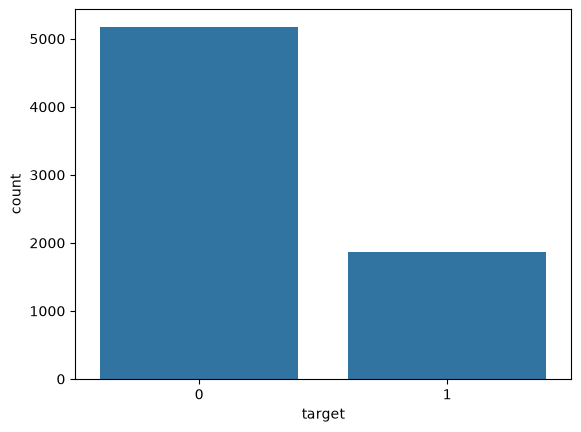

In [22]:
sns.countplot(x='target',data=tele)
plt.show()

## 6. Exploratory Data Analysis
### Numeric features: distributions and relation to the target

In [27]:
numeric_cols=tele.select_dtypes(include='number').columns.drop('target')
numeric_cols

Index(['Tenure Months', 'Monthly Charges', 'Total Charges'], dtype='str')

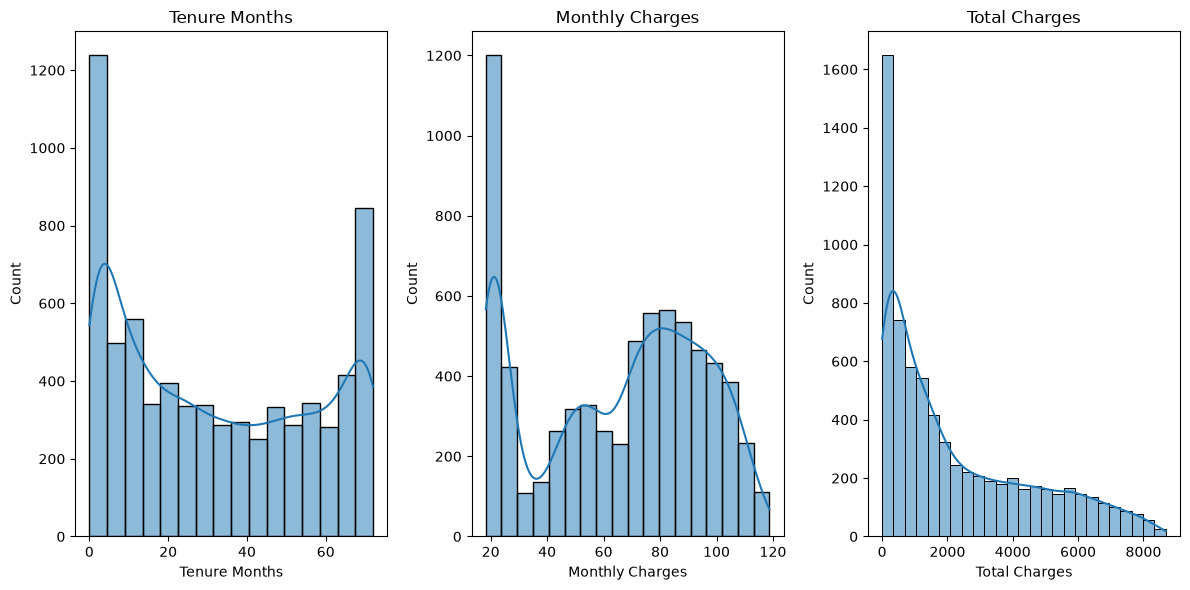

In [28]:
plt.figure(figsize=(12,6))
for i, col in enumerate(numeric_cols):
    plt.subplot(1,len(numeric_cols),i+1)
    sns.histplot(x=col,data=tele,kde=True)
    plt.title(col)
plt.tight_layout()
plt.show()


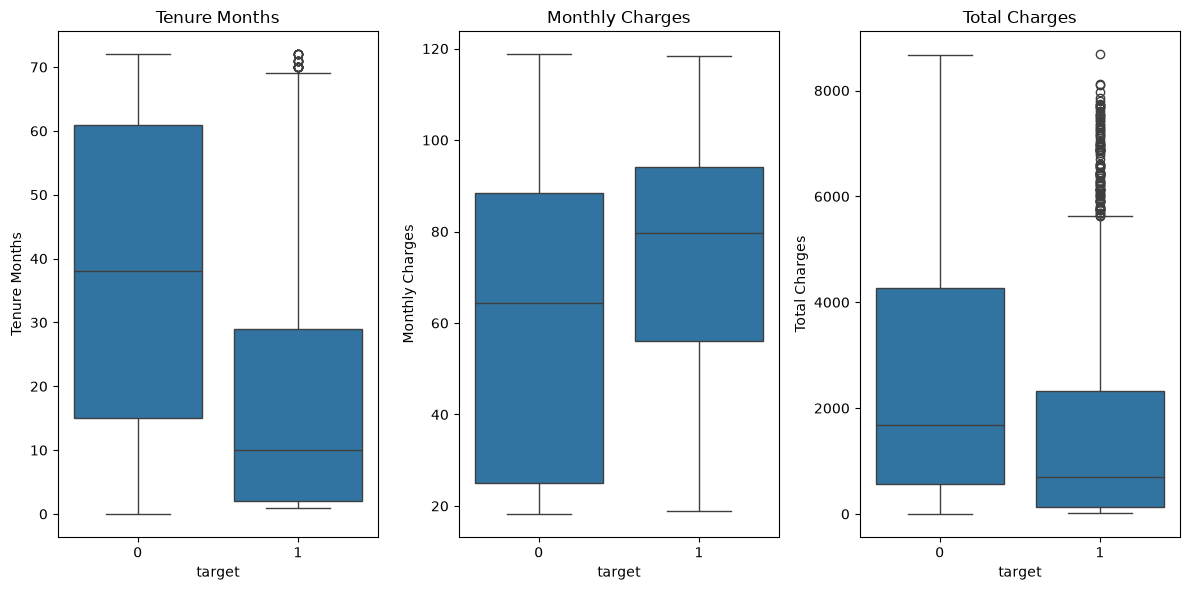

In [29]:
plt.figure(figsize=(12,6))
for i, col in enumerate(numeric_cols):
    plt.subplot(1,len(numeric_cols),i+1)
    sns.boxplot(x='target',y=col,data=tele)
    plt.title(col)
plt.tight_layout()
plt.show()

### Categorical features vs target

In [30]:
cat_cols= tele.select_dtypes(include='object').columns
cat_cols

C:\Users\amroa\AppData\Local\Temp\ipykernel_13636\466274385.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols= tele.select_dtypes(include='object').columns


Index(['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service',
       'Multiple Lines', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV',
       'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method'],
      dtype='str')

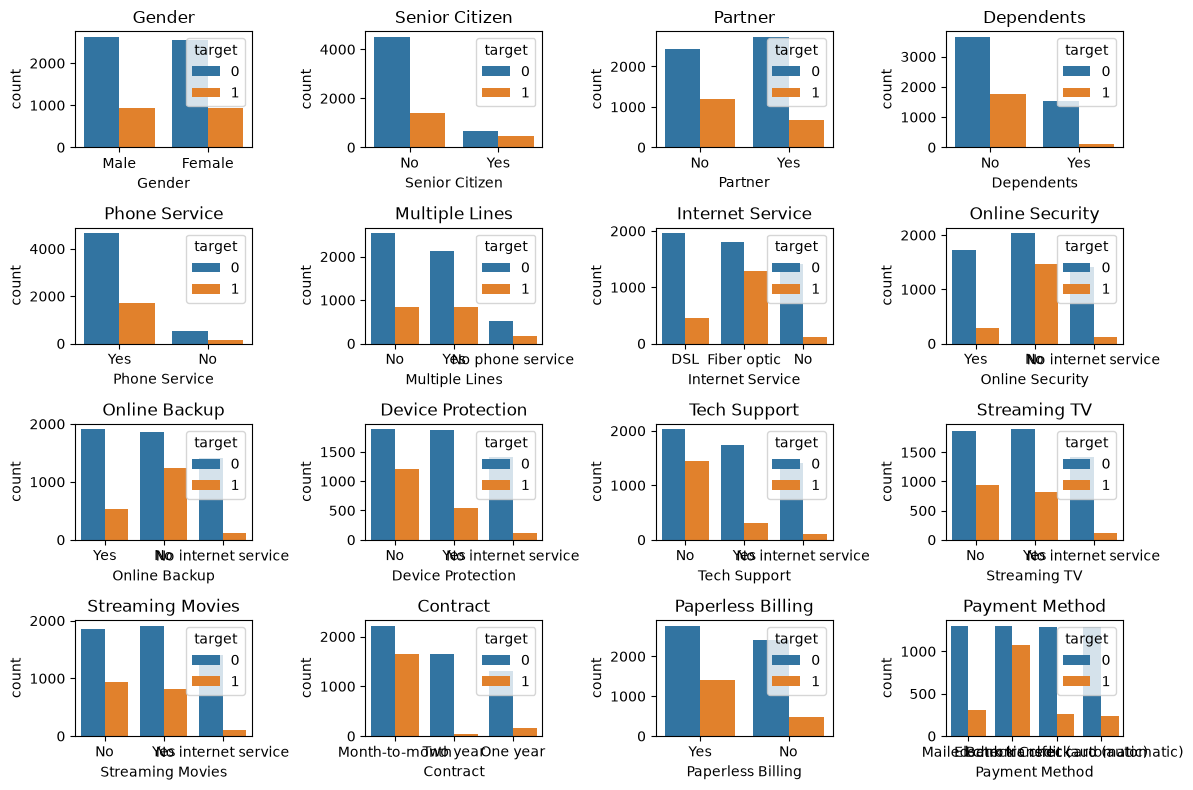

In [31]:
plt.figure(figsize=(12,8))
for i, col in enumerate(cat_cols):
    plt.subplot(4,4,i+1)
    sns.countplot(x=col,data=tele,hue='target')
    plt.title(col)
plt.tight_layout()
plt.show()

### Correlation between numeric features

<Axes: >

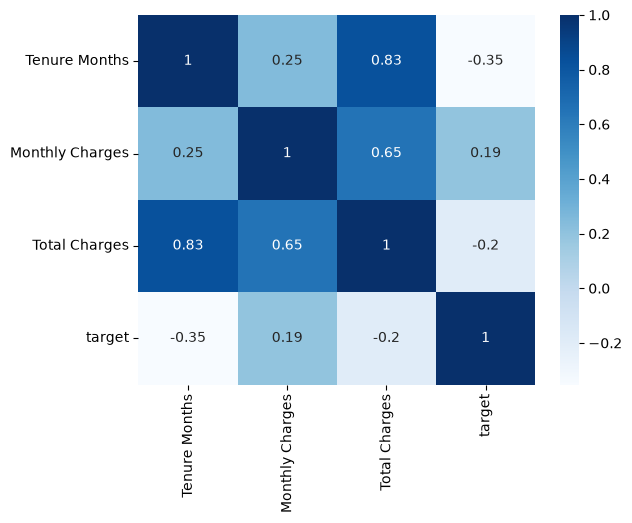

In [32]:
corr = tele.select_dtypes(include='number').corr()
sns.heatmap(corr, annot=True, cmap='Blues')

## 7. Encoding
- `"No internet service"` and `"No phone service"` are merged into `"No"`.
- Categorical columns are one-hot encoded with `get_dummies(drop_first=True)`.

In [33]:
tele = tele.replace({"No internet service": "No", "No phone service": "No"})

In [34]:
# for_incoding1=[]
# for_icodinf2=[]
# cat_cols2= tele.select_dtypes(include='object')
# for col in cat_cols2 :
#     if tele[col].nunique()>2:
#         for_incoding1.append(col)
#     else:
#         for_icodinf2.append(col)

In [35]:
cat_cols_for_icoding=tele.select_dtypes(include='object')

C:\Users\amroa\AppData\Local\Temp\ipykernel_13636\1176513867.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols_for_icoding=tele.select_dtypes(include='object')


In [36]:
tele=pd.get_dummies(tele,columns=cat_cols_for_icoding.columns,dtype=int,drop_first=True)

In [37]:
tele.head()

,Tenure Months,Monthly Charges,Total Charges,target,Gender_Male,Senior Citizen_Yes,Partner_Yes,Dependents_Yes,Phone Service_Yes,Multiple Lines_Yes,...,Device Protection_Yes,Tech Support_Yes,Streaming TV_Yes,Streaming Movies_Yes,Contract_One year,Contract_Two year,Paperless Billing_Yes,Payment Method_Credit card (automatic),Payment Method_Electronic check,Payment Method_Mailed check
0,2,53.85,108.15,1,1,0,0,0,1,0,...,0,0,0,0,0,0,1,0,0,1
1,2,70.70,151.65,1,0,0,0,1,1,0,...,0,0,0,0,0,0,1,0,1,0
2,8,99.65,820.50,1,0,0,0,1,1,1,...,1,0,1,1,0,0,1,0,1,0
3,28,104.80,3046.05,1,0,0,1,1,1,1,...,1,1,1,1,0,0,1,0,1,0
4,49,103.70,5036.30,1,1,0,0,1,1,1,...,1,0,1,1,0,0,1,0,0,0


## 8. Train / Test Split
80% / 20% split with `stratify=y` to keep the same churn ratio in both sets.

In [39]:
X=tele.drop(columns='target')
y=tele['target']
from sklearn.model_selection import  train_test_split
X_train,X_test,y_train,y_test= train_test_split(X,y,stratify=y,test_size=0.2,random_state=42)

## 9. Scaling
`StandardScaler` is applied to the numeric columns only. It is fitted on the training set and then used to transform the test set, so no information leaks from the test data.

In [40]:
from sklearn.preprocessing import  StandardScaler
scaler= StandardScaler()

In [41]:
X_train_Scaler=X_train.copy()
X_test_Scaler=X_test.copy()

In [42]:
X_train_Scaler[numeric_cols]=scaler.fit_transform(X_train_Scaler[numeric_cols])
X_test_Scaler[numeric_cols]=scaler.transform(X_test_Scaler[numeric_cols])

In [43]:
X_train_Scaler.head()

,Tenure Months,Monthly Charges,Total Charges,Gender_Male,Senior Citizen_Yes,Partner_Yes,Dependents_Yes,Phone Service_Yes,Multiple Lines_Yes,Internet Service_Fiber optic,...,Device Protection_Yes,Tech Support_Yes,Streaming TV_Yes,Streaming Movies_Yes,Contract_One year,Contract_Two year,Paperless Billing_Yes,Payment Method_Credit card (automatic),Payment Method_Electronic check,Payment Method_Mailed check
4626,0.102371,-0.521976,-0.262257,1,0,0,0,0,0,0,...,1,0,1,1,0,0,0,0,1,0
4192,-0.711743,0.337478,-0.503635,1,0,1,1,1,0,1,...,0,0,0,0,0,0,0,0,0,1
5457,-0.793155,-0.809013,-0.749883,1,0,1,1,0,0,0,...,0,1,0,0,0,1,0,0,0,1
4717,-0.263980,0.284384,-0.172722,0,0,1,0,1,0,0,...,1,0,1,1,0,1,1,1,0,0
4673,-1.281624,-0.676279,-0.989374,1,0,1,1,1,0,0,...,0,0,0,0,0,0,0,0,1,0


## 10. Handling Imbalance — SMOTENC
Plain SMOTE would create meaningless in-between values for the encoded categorical columns (e.g. 0.4).
`SMOTENC` treats those columns as categorical and only interpolates the numeric ones.

In [44]:
from imblearn.over_sampling import SMOTENC

In [45]:
cat_cols_for_imbalance = []
for i in X_train_Scaler.columns:
    if i not in numeric_cols:
        cat_cols_for_imbalance.append(i)
print(cat_cols_for_imbalance)

['Gender_Male', 'Senior Citizen_Yes', 'Partner_Yes', 'Dependents_Yes', 'Phone Service_Yes', 'Multiple Lines_Yes', 'Internet Service_Fiber optic', 'Internet Service_No', 'Online Security_Yes', 'Online Backup_Yes', 'Device Protection_Yes', 'Tech Support_Yes', 'Streaming TV_Yes', 'Streaming Movies_Yes', 'Contract_One year', 'Contract_Two year', 'Paperless Billing_Yes', 'Payment Method_Credit card (automatic)', 'Payment Method_Electronic check', 'Payment Method_Mailed check']


In [46]:
smotenc = SMOTENC(categorical_features=cat_cols_for_imbalance,random_state=42)
X_train_SMOTENC,y_train_SMOTENC=smotenc.fit_resample(X_train_Scaler,y_train)

In [47]:
y_train_SMOTENC.value_counts()

target
0    4139
1    4139
Name: count, dtype: int64

## 11. Decision Tree
Trained on the SMOTENC data, evaluated on train and test (Accuracy, Recall, F1) to check overfitting.

In [48]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score ,f1_score,recall_score

In [49]:
DecisionTree_MODEL=DecisionTreeClassifier(random_state=42)
DecisionTree_MODEL.fit(X_train_SMOTENC,y_train_SMOTENC)

y_Decisiontree_Pred=DecisionTree_MODEL.predict(X_test_Scaler)
accuracy_DT_test_score=accuracy_score(y_test,y_Decisiontree_Pred)
Recall_DT_test_score=recall_score(y_test,y_Decisiontree_Pred)
F1_DT_test_score=f1_score(y_test,y_Decisiontree_Pred)

print('*Test DecisionTree Scores withour Max_depth*')
print(f'Acuracy Score : {accuracy_DT_test_score}')
print(f'Recall Score : {Recall_DT_test_score}')
print(f'F1 Score : {F1_DT_test_score}')
print()

y_DT_pred_on_train_for_comparison=DecisionTree_MODEL.predict(X_train_SMOTENC)
accuracy_DT_train_score=accuracy_score(y_train_SMOTENC,y_DT_pred_on_train_for_comparison)
Recall_DT_train_score=recall_score(y_train_SMOTENC,y_DT_pred_on_train_for_comparison)
F1_DT_train_score=f1_score(y_train_SMOTENC,y_DT_pred_on_train_for_comparison)

print('*Train DecisionTree Scores withour Max_depth*')
print(f'Acuracy Score : {accuracy_DT_train_score}')
print(f'Recall Score : {Recall_DT_train_score}')
print(f'F1 Score : {F1_DT_train_score}')

*Test DecisionTree Scores withour Max_depth*
Acuracy Score : 0.7260468417317246
Recall Score : 0.5614973262032086
F1 Score : 0.5210918114143921

*Train DecisionTree Scores withour Max_depth*
Acuracy Score : 0.9986711766127084
Recall Score : 0.9975839574776516
F1 Score : 0.9986697303180554


In [50]:
DT_another_code_without_Max_depth=DecisionTreeClassifier(random_state=42)
DT_another_code_without_Max_depth.fit(X_train_SMOTENC,y_train_SMOTENC)
DT_y_predect2_train=DT_another_code_without_Max_depth.predict(X_train_SMOTENC)
DT_accuracy_train=accuracy_score(y_train_SMOTENC,DT_y_predect2_train)
DT_Reacall_train=recall_score(y_train_SMOTENC,DT_y_predect2_train)
DT_F1_train=f1_score(y_train_SMOTENC,DT_y_predect2_train)
DT_y_predect2_test=DT_another_code_without_Max_depth.predict(X_test_Scaler)
DT_accuracy_test=accuracy_score(y_test,DT_y_predect2_test)
DT_Recall_test=recall_score(y_test,DT_y_predect2_test)
DT_F1_test=f1_score(y_test,DT_y_predect2_test)

DT_DataFram = pd.DataFrame({
    'Reports':['Accuracy','Recall','F1','Accuracy','Recall','F1'],
    'Train_test':['Train','Train','Train','Test','Test','Test'],
    'Scores':[DT_accuracy_train,DT_Reacall_train,DT_F1_train,DT_accuracy_test,DT_Recall_test,DT_F1_test]
})
DT_DataFram

,Reports,Train_test,Scores
0,Accuracy,Train,0.998671
1,Recall,Train,0.997584
2,F1,Train,0.998670
3,Accuracy,Test,0.726047
4,Recall,Test,0.561497
5,F1,Test,0.521092


<Axes: xlabel='Reports', ylabel='Scores'>

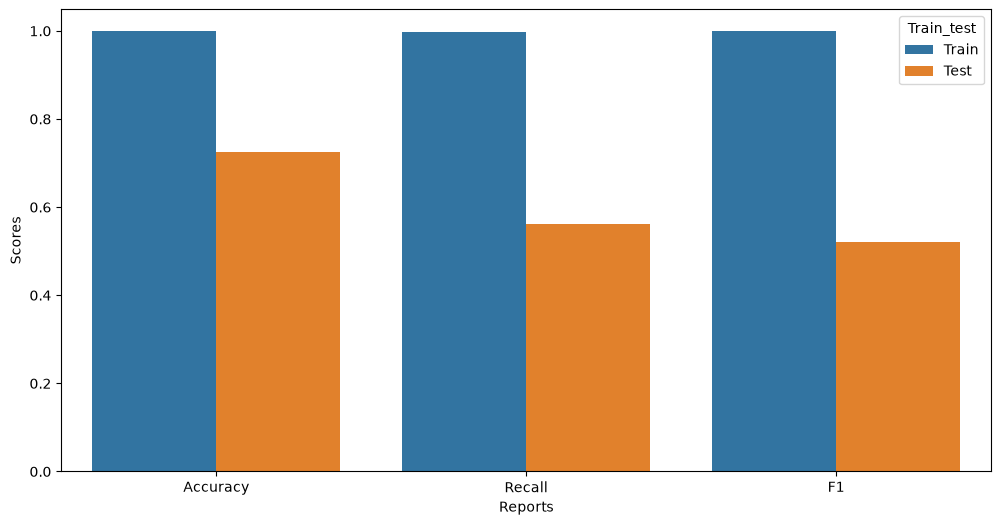

In [51]:
plt.figure(figsize=(12,6))
sns.barplot(x='Reports', y='Scores', hue='Train_test', data=DT_DataFram)

## 12. Bagging
Bagging with Decision Trees, once with `bootstrap=True` (with OOB score) and once with `bootstrap=False`.

In [52]:
from sklearn.ensemble import BaggingClassifier
bag_DT= BaggingClassifier(estimator=DecisionTreeClassifier(random_state=42),
                          n_estimators=100,
                          oob_score=True,
                          random_state=42,
                          n_jobs=-1,
                          max_samples=0.75
                          )
bag_DT.fit(X_train_SMOTENC,y_train_SMOTENC)
print(f'Bagging : | Train :{bag_DT.score(X_train_SMOTENC,y_train_SMOTENC)} | OOb : {bag_DT.oob_score_} | Test : {bag_DT.score(X_test_Scaler,y_test)}')
print(f'Recall Train : {recall_score(y_train_SMOTENC,bag_DT.predict(X_train_SMOTENC))} | Recall test {recall_score(y_test,bag_DT.predict(X_test_Scaler))}')
print(f'Dession Tree without Bagging : {DT_another_code_without_Max_depth.score(X_test_Scaler,y_test)}')


Bagging : | Train :0.9949263107030684 | OOb : 0.8458564870741725 | Test : 0.7686302342086586
Recall Train : 0.9949263107030684 | Recall test 0.6336898395721925
Dession Tree without Bagging : 0.7260468417317246


In [53]:
bag_DT2= BaggingClassifier(estimator=DecisionTreeClassifier(random_state=42),
                          n_estimators=100,
                          bootstrap=False,
                          oob_score=False,
                          max_samples=0.75,
                          random_state=42,
                          n_jobs=-1
                          )
bag_DT2.fit(X_train_SMOTENC,y_train_SMOTENC)
print(f'Bagging : | Train :{bag_DT2.score(X_train_SMOTENC,y_train_SMOTENC)} | Test : {bag_DT2.score(X_test_Scaler,y_test)}')
print(f'Recall Train : {recall_score(y_train_SMOTENC,bag_DT2.predict(X_train_SMOTENC))} | Recall test {recall_score(y_test,bag_DT2.predict(X_test_Scaler))}')
print(f'Dession Tree without Bagging : {DT_another_code_without_Max_depth.score(X_test_Scaler,y_test)}')

Bagging : | Train :0.9986711766127084 | Test : 0.7572746628814763
Recall Train : 0.9987919787388259 | Recall test 0.5989304812834224
Dession Tree without Bagging : 0.7260468417317246


## 13. Pipelines
Scaling and SMOTENC are placed inside an `imblearn` Pipeline, so they are learned from the training data only.
`imblearn.pipeline.Pipeline` is used because the standard scikit-learn Pipeline does not support resampling steps.
### Decision Tree with Pipeline

In [54]:
from sklearn.compose import ColumnTransformer


In [55]:
from imblearn.pipeline import Pipeline

In [56]:
scaler_step=ColumnTransformer(
    [('scale',StandardScaler(),numeric_cols)],
    remainder='passthrough',
    verbose_feature_names_out=False
).set_output(transform='pandas')

In [57]:
pip_DT = Pipeline(
    [
        ('Scaling',scaler_step),
        ('smote',SMOTENC(categorical_features=cat_cols_for_imbalance,random_state=42)),
        ('model',DecisionTreeClassifier(random_state=42))
    ]
)
pip_DT.fit(X_train,y_train)
print(f'Train : {pip_DT.score(X_train,y_train)} | Test : {pip_DT.score(X_test,y_test)}')
print(f'Recall Train : {recall_score(y_train,pip_DT.predict(X_train))} | Recall Test : {recall_score(y_test,pip_DT.predict(X_test))}')


Train : 0.9980475683351083 | Test : 0.7260468417317246
Recall Train : 0.9933110367892977 | Recall Test : 0.5614973262032086


### Bagging with Pipeline

In [58]:
scal_step_for_bagging_just_train_for_me=ColumnTransformer(
    [('scale',StandardScaler(),numeric_cols)],
    remainder='passthrough',
    verbose_feature_names_out=False
).set_output(transform='pandas')

In [59]:
DT_bagging_pipline=Pipeline(
    [
        ('scaling',scal_step_for_bagging_just_train_for_me),
        ('smote',SMOTENC(categorical_features=cat_cols_for_imbalance,random_state=42)),
        ('bagging',BaggingClassifier(
            estimator=DecisionTreeClassifier(random_state=42),
            n_estimators=100,
            bootstrap=True,
            oob_score=True,
            random_state=42,
            max_samples=0.75,
            n_jobs=-1
        ))
    ]
)
DT_bagging_pipline.fit(X_train,y_train)
print(f'Train : {DT_bagging_pipline.score(X_train,y_train)} | oob : {DT_bagging_pipline.named_steps['bagging'].oob_score_} | test : {DT_bagging_pipline.score(X_test,y_test)} ')
print(f'Recall Train : {recall_score(y_train,DT_bagging_pipline.predict(X_train))} | Recall Test : {recall_score(y_test,DT_bagging_pipline.predict(X_test))}')


Train : 0.9929002484913028 | oob : 0.8458564870741725 | test : 0.7686302342086586 
Recall Train : 0.9872909698996656 | Recall Test : 0.6336898395721925


## 14. Random Forest (Pipeline)

In [60]:
from sklearn.ensemble import RandomForestClassifier

In [61]:
RF_pip= Pipeline([
    ('scaling',scal_step_for_bagging_just_train_for_me),
    ('smotenc',SMOTENC(categorical_features=cat_cols_for_imbalance,random_state=42)),
    ('RandomForest',RandomForestClassifier(
        n_estimators=100,
        bootstrap=True,
        oob_score=True,
        random_state=42,
        n_jobs=-1,
        max_samples=0.75,
        max_features='sqrt'
    ))
])
RF_pip.fit(X_train,y_train)
print(f'Train : {RF_pip.score(X_train,y_train)} | oob : {RF_pip.named_steps['RandomForest'].oob_score_} | test : {RF_pip.score(X_test,y_test)}')
print(f'Recall Train : {recall_score(y_train,RF_pip.predict(X_train))} | Recall Test : {recall_score(y_test,RF_pip.predict(X_test))}')


Train : 0.9941427050053249 | oob : 0.8537086252718048 | test : 0.7750177430801988
Recall Train : 0.991304347826087 | Recall Test : 0.6390374331550802


## 15. Boosting (Pipelines)
### AdaBoost

In [62]:
from sklearn.ensemble import AdaBoostClassifier


In [63]:
scal3=ColumnTransformer(
    [('scalling',StandardScaler(),numeric_cols)],
    remainder='passthrough',
    verbose_feature_names_out=False
).set_output(transform='pandas')

In [64]:
adaboost_pip = Pipeline([
    ('Scaling',scal3),
    ('Smotnes',SMOTENC(categorical_features=cat_cols_for_imbalance,random_state=42)),
    ('model',AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1,random_state=42),
        n_estimators=100,
        learning_rate=1.0,
        random_state=42,
    ))
])
adaboost_pip.fit(X_train,y_train)
print(f'Train : {adaboost_pip.score(X_train,y_train)} | Test : {adaboost_pip.score(X_test,y_test)}')
print(f'Recall Train : {recall_score(y_train,adaboost_pip.predict(X_train))} | Recall Test : {recall_score(y_test,adaboost_pip.predict(X_test))}')


Train : 0.7694355697550586 | Test : 0.751596877217885
Recall Train : 0.8147157190635451 | Recall Test : 0.7914438502673797


### Gradient Boosting

In [65]:
from sklearn.ensemble import GradientBoostingClassifier

In [66]:
gradient_scall = ColumnTransformer(
    [('scalling',StandardScaler(),numeric_cols)],
    remainder='passthrough',
    verbose_feature_names_out=False,
).set_output(transform='pandas')

In [67]:
gradient_pip=Pipeline([
    ('scalling',gradient_scall),
    ('smotenc',SMOTENC(categorical_features=cat_cols_for_imbalance,random_state=42)),
    ('model',GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=1.0,
        random_state=42,
        # max_depth=5,
    ))
])
gradient_pip.fit(X_train,y_train)
print(f'Train : {gradient_pip.score(X_train,y_train)} | Test : {gradient_pip.score(X_test,y_test)}')
print(f'Recall Train : {recall_score(y_train,gradient_pip.predict(X_train))} | Recall Test : {recall_score(y_test,gradient_pip.predict(X_test))}')

Train : 0.8746893858714945 | Test : 0.7452093683463449
Recall Train : 0.8107023411371237 | Recall Test : 0.6042780748663101


### XGBoost

In [68]:
from xgboost import XGBClassifier

In [69]:
xgb_pip= Pipeline([
    ('scalling',gradient_scall),
    ('Smotnec',SMOTENC(categorical_features=cat_cols_for_imbalance,random_state=42)),
    ('model',XGBClassifier(
        n_estimators=100,
        learning_rate=0.1,
        objective='binary:logistic',
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1,
        # max_depth=3
    ))
])
xgb_pip.fit(X_train,y_train)
print(f'Train : {xgb_pip.score(X_train,y_train)} | Test : {xgb_pip.score(X_test,y_test)}')
print(f'Recall Train : {recall_score(y_train,xgb_pip.predict(X_train))} | Recall Test : {recall_score(y_test,xgb_pip.predict(X_test))}')

Train : 0.843095491657792 | Test : 0.7679205110007097
Recall Train : 0.8561872909698997 | Recall Test : 0.7272727272727273


### CatBoost

In [70]:
from catboost import CatBoostClassifier

catboost_pip = Pipeline([
    ('scalling', gradient_scall),
    ('smotenc', SMOTENC(
        categorical_features=cat_cols_for_imbalance,
        random_state=42
    )),
    ('model', CatBoostClassifier(
        iterations=100,
        learning_rate=1.0,
        random_seed=42,
        verbose=False
    ))
])

catboost_pip.fit(X_train, y_train)

print(f'Train : {catboost_pip.score(X_train, y_train)} | Test : {catboost_pip.score(X_test, y_test)}')
print(f'Recall Train : {recall_score(y_train, catboost_pip.predict(X_train))} | Recall Test : {recall_score(y_test, catboost_pip.predict(X_test))}')

Train : 0.9369897053603123 | Test : 0.7608232789212207
Recall Train : 0.9096989966555183 | Recall Test : 0.6042780748663101


### LightGBM

In [71]:
from lightgbm import LGBMClassifier

lgbm_pip = Pipeline([
    ('scalling', gradient_scall),
    ('smotenc', SMOTENC(
        categorical_features=cat_cols_for_imbalance,
        random_state=42
    )),
    ('model', LGBMClassifier(
        n_estimators=100,
        learning_rate=0.1,
        num_leaves=31,
        random_state=42,
        verbosity=-1,
        n_jobs=-1
    ))
])

lgbm_pip.fit(X_train, y_train)

print(f'Train : {lgbm_pip.score(X_train, y_train)} | Test : {lgbm_pip.score(X_test, y_test)}')
print(f'Recall Train : {recall_score(y_train, lgbm_pip.predict(X_train))} | Recall Test : {recall_score(y_test, lgbm_pip.predict(X_test))}')

Train : 0.8603123890663826 | Test : 0.7764371894960965
Recall Train : 0.8474916387959867 | Recall Test : 0.6951871657754011


### HistGradientBoosting

In [72]:
from sklearn.ensemble import HistGradientBoostingClassifier

hist_pip = Pipeline([
    ('scalling', gradient_scall),
    ('smotenc', SMOTENC(
        categorical_features=cat_cols_for_imbalance,
        random_state=42
    )),
    ('model', HistGradientBoostingClassifier(
        max_iter=100,
        learning_rate=0.1,
        max_leaf_nodes=31,
        random_state=42
    ))
])

hist_pip.fit(X_train, y_train)

print(f'Train : {hist_pip.score(X_train, y_train)} | Test : {hist_pip.score(X_test, y_test)}')

print(f'Recall Train : {recall_score(y_train, hist_pip.predict(X_train))} | Recall Test : {recall_score(y_test, hist_pip.predict(X_test))}')

Train : 0.8590699325523606 | Test : 0.7643718949609652
Recall Train : 0.8481605351170568 | Recall Test : 0.6898395721925134


## 16. Logistic Regression with `class_weight`
Imbalance handled with `class_weight='balanced'` instead of SMOTENC.

In [73]:
from sklearn.linear_model import LogisticRegression

In [74]:
logistic_scall = ColumnTransformer(
    [('scalling',StandardScaler(),numeric_cols)],
    remainder='passthrough',
    verbose_feature_names_out=False
).set_output(transform='pandas')

In [75]:
logistic_pip = Pipeline([
    ('scaling',logistic_scall),
    ('model',LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ))
]).fit(X_train,y_train)

print(f'Train : {logistic_pip.score(X_train,y_train)} | test {logistic_pip.score(X_test,y_test)}')
print(f'Recall Train : {recall_score(y_train,logistic_pip.predict(X_train))} | Recall test {recall_score(y_test,logistic_pip.predict(X_test))}')


Train : 0.7610933617323393 | test 0.7452093683463449
Recall Train : 0.8180602006688963 | Recall test 0.7780748663101604


## 17. Baseline Comparison — Default Parameters
Logistic Regression, KNN, SVM and Decision Tree trained with default settings and compared on Accuracy, Recall, F1 and ROC-AUC.

In [76]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score

In [77]:
models={
    'Logistic_model':LogisticRegression(),
    'KNN_model':KNeighborsClassifier(),
    'SVM_model':SVC(probability=True),
    'DT_model':DecisionTreeClassifier()
}

In [78]:
all_models_defult_prams_Scores=[]
prediction={}
for name,model in models.items():
    model.fit(X_train_SMOTENC,y_train_SMOTENC)

    y_train_pred_all_models=model.predict(X_train_SMOTENC)
    all_models_train_acuracy_score=accuracy_score(y_train_SMOTENC,y_train_pred_all_models)
    all_models_train_recall_score=recall_score(y_train_SMOTENC,y_train_pred_all_models)
    all_models_train_F1_score=f1_score(y_train_SMOTENC,y_train_pred_all_models)

    y_test_pred_all_models=model.predict(X_test_Scaler)
    all_models_test_acuracy_score=accuracy_score(y_test,y_test_pred_all_models)
    all_models_test_recall_score=recall_score(y_test,y_test_pred_all_models)
    all_models_test_F1_score=f1_score(y_test,y_test_pred_all_models)

    train_prop_all_models=model.predict_proba(X_train_SMOTENC)[:,1]
    test_prop_all_models=model.predict_proba(X_test_Scaler)[:,1]
    all_models_train_Roc_score=roc_auc_score(y_train_SMOTENC,train_prop_all_models)
    all_models_test_Roc_score=roc_auc_score(y_test,test_prop_all_models)

    scores=({
        'Model': name,
        'Accuracy Train': all_models_train_acuracy_score,
        'Accuracy Test': all_models_test_acuracy_score,
        'Recall Train': all_models_train_recall_score,
        'Recall Test': all_models_test_recall_score,
        'F1 Train': all_models_train_F1_score,
        'F1 Test': all_models_test_F1_score,
        'Roc Train':all_models_train_Roc_score,
        'Roc test':all_models_test_Roc_score
    })
    if name =='DT_model':
        scores['Tree Depth']=model.get_depth()
        scores['Tree Leaves']=model.get_n_leaves()
    all_models_defult_prams_Scores.append(scores)

    prediction[name]=y_test_pred_all_models


c:\Users\amroa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [79]:
models_scores_DataFrame=pd.DataFrame(all_models_defult_prams_Scores).sort_values('Roc test',ascending=True)
models_scores_DataFrame

,Model,Accuracy Train,Accuracy Test,Recall Train,Recall Test,F1 Train,F1 Test,Roc Train,Roc test,Tree Depth,Tree Leaves
3,DT_model,0.998671,0.721789,0.997584,0.577540,0.998670,0.524272,0.999996,0.675522,36.0,1351.0
1,KNN_model,0.870379,0.732434,0.950471,0.745989,0.879991,0.596791,0.962322,0.793792,NaN,NaN
2,SVM_model,0.837521,0.755855,0.899976,0.748663,0.847072,0.619469,0.914574,0.833851,NaN,NaN
0,Logistic_model,0.792341,0.747339,0.832568,0.780749,0.800372,0.621277,0.880361,0.843037,NaN,NaN


C:\Users\amroa\AppData\Local\Temp\ipykernel_13636\3275852277.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax=sns.barplot(x='Model',y='Accuracy Test',data=models_scores_DataFrame,palette='viridis')


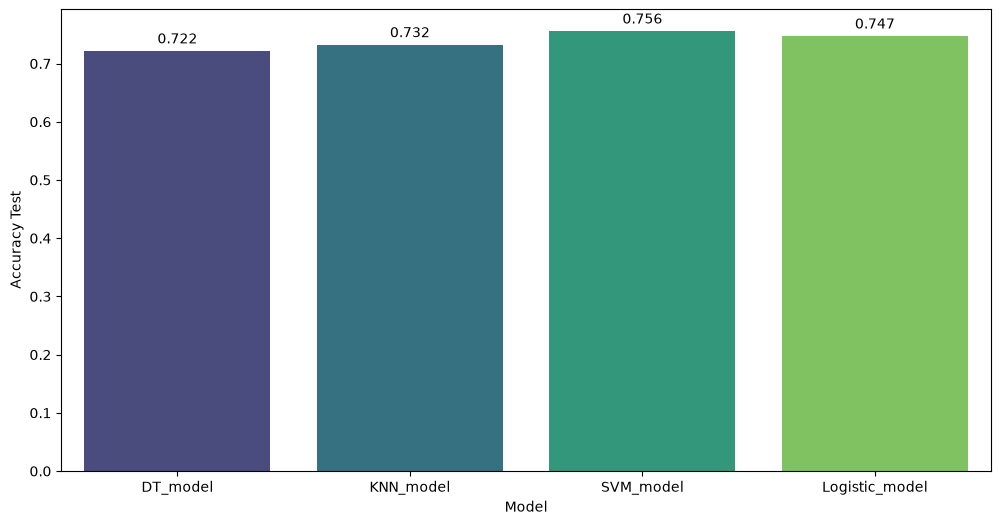

In [80]:
plt.figure(figsize=(12,6))
ax=sns.barplot(x='Model',y='Accuracy Test',data=models_scores_DataFrame,palette='viridis')
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=3)
plt.show()

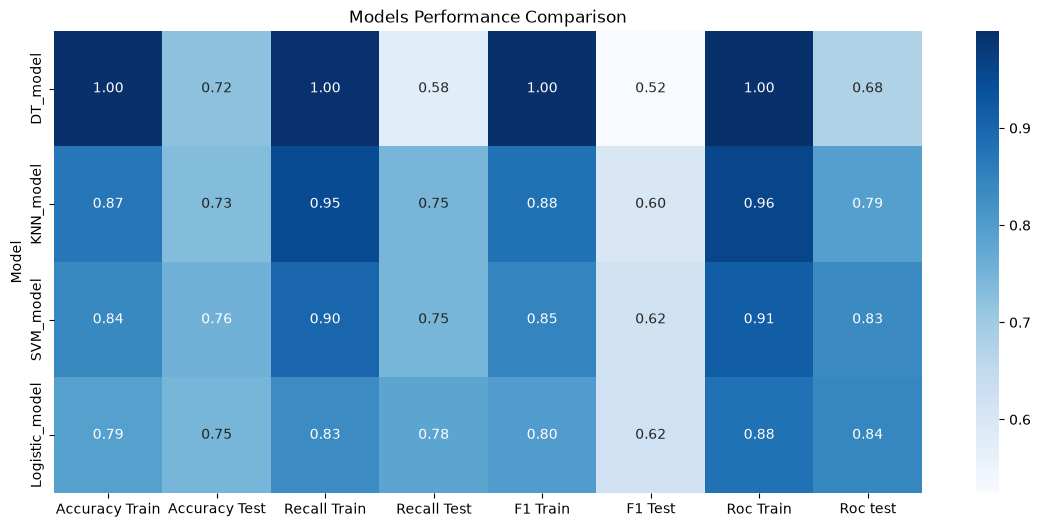

In [81]:
plt.figure(figsize=(14, 6))

sns.heatmap(
    models_scores_DataFrame.set_index('Model')[
        ['Accuracy Train', 'Accuracy Test',
         'Recall Train', 'Recall Test',
         'F1 Train', 'F1 Test',
         'Roc Train', 'Roc test']
    ],
    annot=True,
    fmt='.2f',
    cmap='Blues'
)

plt.title('Models Performance Comparison')
plt.show()

## 18. Hyperparameter Tuning — GridSearchCV
### Models dictionary and first parameter grid
`count_fits` calculates the total number of trainings: `combinations × cv folds`.

In [82]:
from sklearn.model_selection import GridSearchCV

In [83]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

In [84]:
models={
    'Logistic_model':LogisticRegression(max_iter=1000, random_state=42),
    'KNN_model':KNeighborsClassifier(),
    'SVM_model':SVC(probability=True,random_state=42),
    'DTree_model':DecisionTreeClassifier(random_state=42),

    'Bagging':BaggingClassifier(random_state=42, n_jobs=-1),
    'Ada_boost':AdaBoostClassifier(estimator=DecisionTreeClassifier(random_state=42), random_state=42),

    'Random_forest_model':RandomForestClassifier(random_state=42, n_jobs=-1),
    'Gradient_boost':GradientBoostingClassifier(random_state=42),
    'Hist_boost':HistGradientBoostingClassifier(random_state=42),
    'XGB':XGBClassifier(random_state=42, n_jobs=-1),
    'LightGBM':LGBMClassifier(random_state=42, n_jobs=-1),
    'Cat_boost':CatBoostClassifier(random_state=42, verbose=False)
}

In [85]:
from sklearn.model_selection import ParameterGrid


In [86]:
params_Grid = {
    'Logistic_model':{
        'C':[0.1,0.5,1,2,3,5,10,20,50],
    },
    'KNN_model':{
        'n_neighbors':[1,3,5,7,8,10,15,20,30,35],
        'weights':['distance','uniform'],
        'metric':['manhattan','euclidean'],
    },
    'SVM_model':{
        'C':[0.1,0.5,1,2,3,5,10,20,50],
        'kernel':['linear','rbf'],
        'gamma': ['scale', 0.01, 0.1, 1],
    },
    'DTree_model':{
        'max_depth':[1,2,3,4,5,6,7,8,9,10,15,20],
        'min_samples_split':[2,4,5,6,8,10,15,20,30,50],
        'min_samples_leaf':[1,2,5,8,11,15,15,17,20,30],
        'criterion': ['gini', 'entropy'],
    },
    'Bagging':[
        {
            'estimator':[DecisionTreeClassifier(random_state=42)],
            'estimator__max_depth':[None,1,2,3,5,7,10,15],
            'n_estimators':[10,20,50,70,100,130],
            'max_samples':[0.5,0.6,0.7,0.750,0.8],
            'estimator__min_samples_split': [2, 10, 20, 50],
            'estimator__min_samples_leaf': [1, 5, 10, 20],
            'estimator__criterion': ['gini', 'entropy']
        },
        {
            'estimator':[LogisticRegression(max_iter=1000,random_state=42)],
            'estimator__C':[0.1,0.5,1,2,3,5,10,20,50],
            'n_estimators':[10,20,50,70,100,130],
            'max_samples':[0.5,0.6,0.7,0.750,0.8],
        }
    ],
    'Random_forest_model':{
        'n_estimators':[10,20,50,70,100,130],
        'max_depth':[1,2,3,4,5,6,7,8,9,10,15,20],
        'min_samples_split':[2,4,5,6,8,10,15,20,30,50],
        'min_samples_leaf':[1,2,5,8,11,15,15,17,20,30],
        'max_features': ['sqrt', 'log2', 0.5, None],
        'criterion': ['gini', 'entropy'],
        'max_samples': [0.5, 0.75,0.8]
    },
    'Ada_boost':{
        'n_estimators':[10,20,50,70,100,130],
        'learning_rate':[0.01,0.1,0.2,0.3,0.5,0.6,1.0],
        'estimator__max_depth':[1,2,3,5,7,10],
        'estimator__min_samples_split':[2,4,5,6,8,10,15,20,30,50],
        'estimator__min_samples_leaf':[1,2,5,8,11,15,17,20,30],
    },
    'Gradient_boost':{
        'n_estimators':[10,20,50,70,100,130],
        'learning_rate':[0.01,0.1,0.2,0.3,0.5,0.6,1.0],
        'max_depth':[1,2,3,5,7,10,15],
        'min_samples_split':[2,4,5,6,8,10,15,20,30,50],
        'min_samples_leaf':[1,2,5,8,11,15,17,20,30],
        'subsample': [0.5, 0.8, 1.0],
        'max_features': ['sqrt', None]
    },
    'Hist_boost' :{
        'max_iter':[10,20,50,70,100,130],
        'learning_rate':[0.01,0.1,0.2,0.3,0.5,0.6,1.0],
        'max_depth':[1,2,3,5,7,10,15],
        'min_samples_leaf':[1,2,5,8,11,15,17,20,30],
        'max_features':[0.5,0.8,1.0],
        'max_leaf_nodes':[3,5,10,15,31,63],
        'l2_regularization':[0,0.1,1.0] 
    },
    'XGB':{
        'n_estimators':[10,20,50,70,100,130],
        'learning_rate':[0.01,0.1,0.5,1.0],
        'max_depth':[1,2,3,5,7,10],
        'subsample':[0.5,0.8,1.0],
        'colsample_bytree':[0.5,0.8,1.0],
        'min_child_weight':[1,5,10],
        'gamma':[0,0.1,1],
        'reg_lambda':[0,1,10],
        'reg_alpha':[0,0.1,1]
    },
    'LightGBM':{
        'n_estimators':[10,20,50,70,100,130],
        'learning_rate':[0.01,0.1,0.5,1.0],
        'num_leaves':[15,31,63],
        'max_depth':[-1,3,5,7,10],
        'min_child_samples':[5,10,20,30],
        'subsample':[0.5,0.8,1.0],
        'subsample_freq':[1],
        'colsample_bytree':[0.5,0.8,1.0],
        'reg_lambda':[0,1,10],
        'reg_alpha':[0,0.1,1]
    },
    'Cat_boost':{
        'iterations':[10,20,50,70,100,130],
        'learning_rate':[0.01,0.1,0.5,1.0],
        'depth':[2,4,6,8,10],
        'l2_leaf_reg':[1,3,5,10],
        'random_strength':[0,1,5],
        'bagging_temperature':[0,1],
        'rsm':[0.5,0.8,1.0]
    },
}

In [87]:
def count_fits(params_grid, cv=5):
    total = 0
    for model_name, grid in params_grid.items():
        n = len(ParameterGrid(grid))
        fits = n * cv
        print(f'{model_name}: {n} combinations -> {fits} fits')
        total += fits
    print(f'Total fits: {total}')
    return total

count_fits(params_Grid, cv=5)

Logistic_model: 9 combinations -> 45 fits
KNN_model: 40 combinations -> 200 fits
SVM_model: 72 combinations -> 360 fits
DTree_model: 2400 combinations -> 12000 fits
Bagging: 7950 combinations -> 39750 fits
Random_forest_model: 172800 combinations -> 864000 fits
Ada_boost: 22680 combinations -> 113400 fits
Gradient_boost: 158760 combinations -> 793800 fits
Hist_boost: 142884 combinations -> 714420 fits
XGB: 104976 combinations -> 524880 fits
LightGBM: 116640 combinations -> 583200 fits
Cat_boost: 8640 combinations -> 43200 fits
Total fits: 3689255


3689255

### :o
## What is this !

### Reduced parameter grid
Smaller grid to keep the search practical. Every parameter name starts with `model__` because the model is the step named `model` inside the Pipeline.

In [88]:
params_Grid2 = {
    'Logistic_model':{
        'model__C':[0.01,0.1,1,10,50],
    },
    'KNN_model':{
        'model__n_neighbors':[3,5,7,11,15,21,31],
        'model__weights':['distance','uniform'],
        'model__metric':['manhattan','euclidean'],
    },
    'SVM_model':[
        {
            'model__kernel':['linear'],
            'model__C':[0.1,1,10,50],
        },
        {
            'model__kernel':['rbf'],
            'model__C':[0.1,1,10,50],
            'model__gamma':['scale',0.01,0.1],
        }
    ],
    'DTree_model':{
        'model__max_depth':[None,3,5,7,10,15],
        'model__min_samples_leaf':[1,5,10,20,30],
    },
    'Bagging':[
        {
            'model__estimator':[DecisionTreeClassifier(random_state=42)],
            'model__estimator__max_depth':[None,5,10],
            'model__estimator__min_samples_leaf':[1,5,10],
            'model__n_estimators':[50,100,200],
            'model__max_samples':[0.5,0.75,1.0],
        },
        {
            'model__estimator':[LogisticRegression(max_iter=1000,random_state=42)],
            'model__estimator__C':[0.1,1,10],
            'model__n_estimators':[50,100],
            'model__max_samples':[0.5,0.75],
        }
    ],
    'Random_forest_model':{
        'model__n_estimators':[100,200,300],
        'model__max_depth':[None,5,10,15],
        'model__min_samples_leaf':[1,5,10],
        'model__max_features':['sqrt',0.5],
        'model__max_samples':[0.5,0.75,None],
    },
    'Ada_boost':{
        'model__n_estimators':[50,100,200],
        'model__learning_rate':[0.05,0.1,0.3,0.5,1.0],
        'model__estimator__max_depth':[1,2,3],
        'model__estimator__min_samples_leaf':[1,10,20],
    },
    'Gradient_boost':{
        'model__n_estimators':[50,100,200],
        'model__learning_rate':[0.05,0.1,0.3],
        'model__max_depth':[2,3,4,5],
        'model__min_samples_leaf':[1,10,20],
        'model__subsample':[0.8,1.0],
    },
    'Hist_boost':{
        'model__max_iter':[50,100,200],
        'model__learning_rate':[0.05,0.1,0.3],
        'model__min_samples_leaf':[10,20,30],
        'model__max_leaf_nodes':[15,31],
        'model__l2_regularization':[0,1.0],
    },
    'XGB':{
        'model__n_estimators':[50,100,200],
        'model__learning_rate':[0.05,0.1,0.3],
        'model__max_depth':[3,5,7],
        'model__subsample':[0.8,1.0],
        'model__colsample_bytree':[0.8,1.0],
        'model__min_child_weight':[1,5],
        'model__reg_lambda':[1,10],
    },
    'LightGBM':{
        'model__n_estimators':[50,100,200],
        'model__learning_rate':[0.05,0.1,0.3],
        'model__num_leaves':[15,31,63],
        'model__min_child_samples':[10,20,30],
        'model__subsample':[0.8,1.0],
        'model__subsample_freq':[1],
        'model__colsample_bytree':[0.8,1.0],
    },
    'Cat_boost':{
        'model__iterations':[100,200,300],
        'model__learning_rate':[0.05,0.1,0.3],
        'model__depth':[4,6,8],
        'model__l2_leaf_reg':[1,3,10],
        'model__rsm':[0.8,1.0],
    },
}

In [89]:
count_fits(params_Grid2, cv=5)

Logistic_model: 5 combinations -> 25 fits
KNN_model: 28 combinations -> 140 fits
SVM_model: 16 combinations -> 80 fits
DTree_model: 30 combinations -> 150 fits
Bagging: 93 combinations -> 465 fits
Random_forest_model: 216 combinations -> 1080 fits
Ada_boost: 135 combinations -> 675 fits
Gradient_boost: 216 combinations -> 1080 fits
Hist_boost: 108 combinations -> 540 fits
XGB: 432 combinations -> 2160 fits
LightGBM: 324 combinations -> 1620 fits
Cat_boost: 162 combinations -> 810 fits
Total fits: 8825


8825

### Setup

In [90]:
import warnings
warnings.filterwarnings("ignore")

In [91]:
from sklearn.model_selection import GridSearchCV


In [92]:
scalling_for_grid_search = ColumnTransformer(
    [('Scalling',StandardScaler(),numeric_cols)],
    remainder='passthrough',
    verbose_feature_names_out=False,
).set_output(transform='pandas')

In [93]:
from sklearn.metrics import precision_score, average_precision_score


## 19. Grid Search — Path A: SMOTENC
Pipeline: `Scaling → SMOTENC → model`, 5-fold CV, `scoring='f1'`.
Resampling happens inside each fold, so the validation fold always contains real data only.
Models are ranked by `CV F1` (`best_score_`), not by test results.

In [94]:
Grid_search={}
scores=[]
for name,grid in params_Grid2.items():
    pip_for_grid_search=Pipeline([
    ('scalling',scalling_for_grid_search ),
    ('smotnec',SMOTENC(categorical_features=cat_cols_for_imbalance,random_state=42)),
    ('model',models[name])
])
    search= GridSearchCV(pip_for_grid_search,grid,cv=5,scoring='f1',n_jobs=-1)
    search.fit(X_train,y_train)
    Grid_search[name]=search
    best_CV= search.best_estimator_
    y_train_pred = best_CV.predict(X_train)
    y_test_pred = best_CV.predict(X_test)
    y_test_prop =best_CV.predict_proba(X_test)[:,1]

    scores.append({
        'Model':name,
        'CV F1':search.best_score_,
        'Accuracy Train':accuracy_score(y_train,y_train_pred),
        'Accuracy Test':accuracy_score(y_test,y_test_pred),
        'Precision':precision_score(y_test,y_test_pred),
        'Recall Train':recall_score(y_train,y_train_pred),
        'Recall Test':recall_score(y_test,y_test_pred),
        'F1 Train':f1_score(y_train,y_train_pred),
        'F1 Test':f1_score(y_test,y_test_pred),
        'ROC-AUC':roc_auc_score(y_test,y_test_prop),
        'PR-AUC':average_precision_score(y_test,y_test_prop),
    })
results_df = (
    pd.DataFrame(scores)
    .sort_values('CV F1', ascending=False)
    .reset_index(drop=True)
)
results_df

,Model,CV F1,Accuracy Train,Accuracy Test,Precision,Recall Train,Recall Test,F1 Train,F1 Test,ROC-AUC,PR-AUC
0,Random_forest_model,0.652688,0.810437,0.772889,0.552734,0.815385,0.756684,0.695379,0.638826,0.853188,0.658244
1,Ada_boost,0.652099,0.770323,0.750177,0.519435,0.812709,0.786096,0.652524,0.625532,0.847027,0.662941
2,XGB,0.652003,0.786830,0.763662,0.538606,0.805351,0.764706,0.667221,0.632044,0.847701,0.657104
3,Gradient_boost,0.649989,0.781328,0.757984,0.530726,0.806020,0.762032,0.661724,0.625686,0.846351,0.660497
4,SVM_model,0.646880,0.780440,0.758694,0.532819,0.784615,0.737968,0.654759,0.618834,0.841527,0.615116
5,Bagging,0.646382,0.767306,0.746629,0.515098,0.796656,0.775401,0.645004,0.618997,0.844114,0.641595
6,LightGBM,0.646283,0.783280,0.770759,0.548387,0.800000,0.772727,0.662054,0.641509,0.849162,0.658213
7,Cat_boost,0.645051,0.785410,0.766501,0.542694,0.799331,0.764706,0.664073,0.634850,0.851244,0.663839
8,Logistic_model,0.643174,0.764821,0.746629,0.515098,0.790635,0.775401,0.640824,0.618997,0.843468,0.640642
9,Hist_boost,0.641523,0.778310,0.761533,0.535714,0.804013,0.762032,0.658089,0.629139,0.848676,0.656876


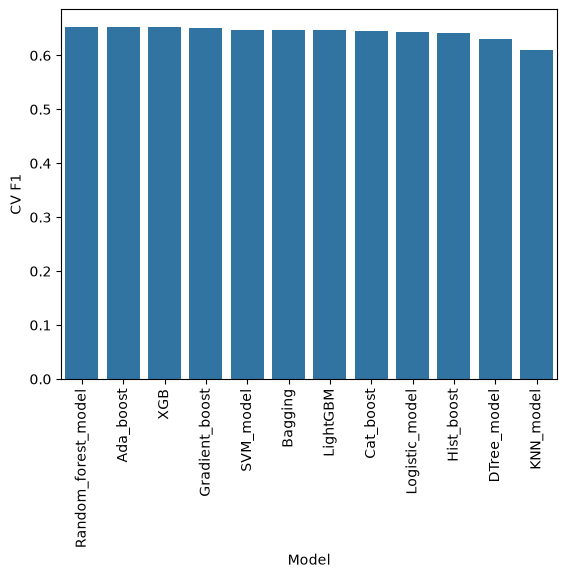

In [113]:
sns.barplot(x='Model',y='CV F1',data=results_df)
plt.xticks(rotation=90)
plt.show()

## 20. Grid Search — Path B: `class_weight`
Pipeline: `Scaling → model`, with the imbalance handled inside each model:
- `class_weight='balanced'` for most models
- `scale_pos_weight = neg / pos` for XGBoost
- `auto_class_weights='Balanced'` for CatBoost
- inside the base estimator for Bagging and AdaBoost

KNN and Gradient Boosting are excluded because they do not support class weights.

In [95]:
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
models_Class_weight={
    'Logistic_model':LogisticRegression(max_iter=1000, random_state=42,class_weight='balanced'),
    'SVM_model':SVC(probability=True,random_state=42,class_weight='balanced'),
    'DTree_model':DecisionTreeClassifier(random_state=42,class_weight='balanced'),

    'Bagging':BaggingClassifier(random_state=42, n_jobs=1),
    'Ada_boost':AdaBoostClassifier(estimator=DecisionTreeClassifier(random_state=42, class_weight='balanced'), random_state=42),

    'Random_forest_model':RandomForestClassifier(random_state=42, n_jobs=1,class_weight='balanced'),
    'Hist_boost':HistGradientBoostingClassifier(random_state=42,class_weight='balanced'),
    'XGB':XGBClassifier(random_state=42, n_jobs=1,scale_pos_weight=neg / pos),
    'LightGBM':LGBMClassifier(random_state=42, n_jobs=1,class_weight='balanced'),
    'Cat_boost':CatBoostClassifier(random_state=42, verbose=False,auto_class_weights='Balanced')
}

In [96]:
params_Grid3 = {
    'Logistic_model':{
        'model__C':[0.01,0.1,1,10,50],
    },
    'SVM_model':[
        {
            'model__kernel':['linear'],
            'model__C':[0.1,1,10,50],
        },
        {
            'model__kernel':['rbf'],
            'model__C':[0.1,1,10,50],
            'model__gamma':['scale',0.01,0.1],
        }
    ],
    'DTree_model':{
        'model__max_depth':[None,3,5,7,10,15],
        'model__min_samples_leaf':[1,5,10,20,30],
    },
    'Bagging':[
        {
            'model__estimator':[DecisionTreeClassifier(random_state=42,class_weight='balanced')],
            'model__estimator__max_depth':[None,5,10],
            'model__estimator__min_samples_leaf':[1,5,10],
            'model__n_estimators':[50,100,200],
            'model__max_samples':[0.5,0.75,1.0],
        },
        {
            'model__estimator':[LogisticRegression(max_iter=1000,random_state=42,class_weight='balanced')],
            'model__estimator__C':[0.1,1,10],
            'model__n_estimators':[50,100],
            'model__max_samples':[0.5,0.75],
        }
    ],
    'Random_forest_model':{
        'model__n_estimators':[100,200,300],
        'model__max_depth':[None,5,10,15],
        'model__min_samples_leaf':[1,5,10],
        'model__max_features':['sqrt',0.5],
        'model__max_samples':[0.5,0.75,None],
    },
    'Ada_boost':{
        'model__n_estimators':[50,100,200],
        'model__learning_rate':[0.05,0.1,0.3,0.5,1.0],
        'model__estimator__max_depth':[1,2,3],
        'model__estimator__min_samples_leaf':[1,10,20],
    },
    'Hist_boost':{
        'model__max_iter':[50,100,200],
        'model__learning_rate':[0.05,0.1,0.3],
        'model__min_samples_leaf':[10,20,30],
        'model__max_leaf_nodes':[15,31],
        'model__l2_regularization':[0,1.0],
    },
    'XGB':{
        'model__n_estimators':[50,100,200],
        'model__learning_rate':[0.05,0.1,0.3],
        'model__max_depth':[3,5,7],
        'model__subsample':[0.8,1.0],
        'model__colsample_bytree':[0.8,1.0],
        'model__min_child_weight':[1,5],
        'model__reg_lambda':[1,10],
    },
    'LightGBM':{
        'model__n_estimators':[50,100,200],
        'model__learning_rate':[0.05,0.1,0.3],
        'model__num_leaves':[15,31,63],
        'model__min_child_samples':[10,20,30],
        'model__subsample':[0.8,1.0],
        'model__subsample_freq':[1],
        'model__colsample_bytree':[0.8,1.0],
    },
    'Cat_boost':{
        'model__iterations':[100,200,300],
        'model__learning_rate':[0.05,0.1,0.3],
        'model__depth':[4,6,8],
        'model__l2_leaf_reg':[1,3,10],
        'model__rsm':[0.8,1.0],
    },
}

In [97]:
Grid_search_Class_wight={}
scores_class_wight=[]
for name,grid in params_Grid3.items():
    pip_for_grid_search2=Pipeline([
    ('scalling',scalling_for_grid_search ),
    ('model',models_Class_weight[name])
])
    search= GridSearchCV(pip_for_grid_search2,grid,cv=5,scoring='f1',n_jobs=-1)
    search.fit(X_train,y_train)
    Grid_search_Class_wight[name]=search
    best_CV= search.best_estimator_
    y_train_pred = best_CV.predict(X_train)
    y_test_pred = best_CV.predict(X_test)
    y_test_prop =best_CV.predict_proba(X_test)[:,1]

    scores_class_wight.append({
        'Model':name,
        'CV F1':search.best_score_,
        'Accuracy Train':accuracy_score(y_train,y_train_pred),
        'Accuracy Test':accuracy_score(y_test,y_test_pred),
        'Precision':precision_score(y_test,y_test_pred),
        'Recall Train':recall_score(y_train,y_train_pred),
        'Recall Test':recall_score(y_test,y_test_pred),
        'F1 Train':f1_score(y_train,y_train_pred),
        'F1 Test':f1_score(y_test,y_test_pred),
        'ROC-AUC':roc_auc_score(y_test,y_test_prop),
        'PR-AUC':average_precision_score(y_test,y_test_prop),
    })
results_df2 = (
    pd.DataFrame(scores_class_wight)
    .sort_values('CV F1', ascending=False)
    .reset_index(drop=True)
)
results_df2

,Model,CV F1,Accuracy Train,Accuracy Test,Precision,Recall Train,Recall Test,F1 Train,F1 Test,ROC-AUC,PR-AUC
0,Random_forest_model,0.653806,0.835286,0.766501,0.541436,0.917726,0.786096,0.747277,0.641221,0.853125,0.662385
1,XGB,0.652843,0.775825,0.751597,0.520548,0.865552,0.812834,0.672033,0.634656,0.854105,0.672543
2,Bagging,0.651408,0.811324,0.773598,0.552182,0.832107,0.778075,0.700648,0.645949,0.855412,0.661890
3,Cat_boost,0.650091,0.783103,0.752307,0.521664,0.856856,0.804813,0.677061,0.633018,0.858114,0.676775
4,LightGBM,0.649929,0.796415,0.759404,0.530435,0.874916,0.815508,0.695190,0.642782,0.856650,0.672691
5,Hist_boost,0.648837,0.790557,0.755145,0.525483,0.868896,0.799465,0.687665,0.634146,0.853670,0.671815
6,Ada_boost,0.646654,0.770678,0.748048,0.517495,0.791973,0.751337,0.646995,0.612868,0.838407,0.598716
7,Logistic_model,0.642164,0.761803,0.743080,0.510453,0.818060,0.783422,0.645723,0.618143,0.847942,0.640657
8,SVM_model,0.640737,0.780618,0.755855,0.526224,0.850836,0.804813,0.673016,0.636364,0.841220,0.614003
9,DTree_model,0.631442,0.777245,0.750887,0.520354,0.844816,0.786096,0.668077,0.626198,0.839902,0.633240


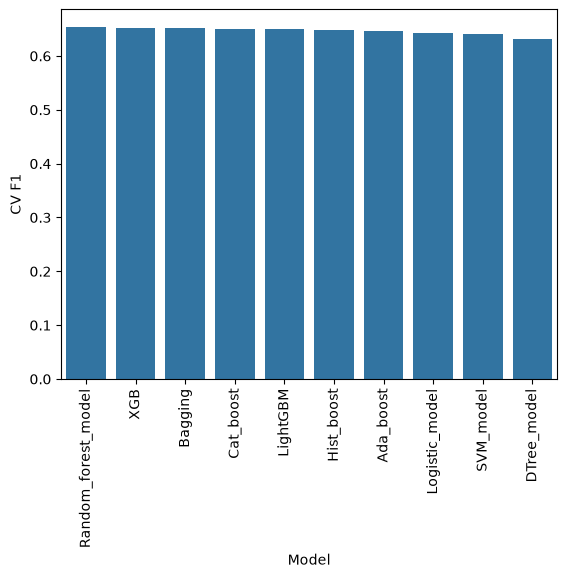

In [114]:
sns.barplot(x='Model',y='CV F1',data=results_df2)
plt.xticks(rotation=90)
plt.show()

## 21. Voting
Top 3 models from Path B (Random Forest, XGBoost, Bagging) combined with soft and hard voting, evaluated with 5-fold CV F1.

In [116]:
from sklearn.ensemble import VotingClassifier
from sklearn.model_selection import cross_val_score

In [117]:
voting = VotingClassifier(
    estimators=[
        ('rf', Grid_search_Class_wight['Random_forest_model'].best_estimator_),
        ('xgb', Grid_search_Class_wight['XGB'].best_estimator_),
        ('bag', Grid_search_Class_wight['Bagging'].best_estimator_),
    ],
    voting='soft'
)

cv_f1 = cross_val_score(voting, X_train, y_train, cv=5, scoring='f1', n_jobs=-1)
print(cv_f1)
print(cv_f1.mean())

[0.66111111 0.67036011 0.65181058 0.66756757 0.62023653]
0.6542171810641282


In [125]:
voting2 = VotingClassifier(
    estimators=[
        ('rf', Grid_search_Class_wight['Random_forest_model'].best_estimator_),
        ('xgb', Grid_search_Class_wight['XGB'].best_estimator_),
        ('bag', Grid_search_Class_wight['Bagging'].best_estimator_),
    ],
    voting='hard'
)

cv_f1 = cross_val_score(voting2, X_train, y_train, cv=5, scoring='f1', n_jobs=-1)
print(cv_f1)
print(cv_f1.mean())

[0.65833333 0.6740638  0.65368567 0.67302452 0.62169312]
0.6561600906025188


## 22. Final Model — XGBoost (`class_weight`)
The top models were almost tied on CV F1 (difference < 0.003), so the model with the smallest gap between F1 Train and CV F1 was chosen (less overfitting).
Evaluated **once** on the test set.

In [118]:
from sklearn.metrics import classification_report, confusion_matrix

final_model = Grid_search_Class_wight['XGB'].best_estimator_
y_test_final = final_model.predict(X_test)

print(classification_report(y_test, y_test_final))
print(confusion_matrix(y_test, y_test_final))

              precision    recall  f1-score   support

           0       0.92      0.73      0.81      1035
           1       0.52      0.81      0.63       374

    accuracy                           0.75      1409
   macro avg       0.72      0.77      0.72      1409
weighted avg       0.81      0.75      0.76      1409

[[755 280]
 [ 70 304]]


## 23. Feature Importance

In [119]:
importances = final_model.named_steps['model'].feature_importances_
feature_names = final_model.named_steps['scalling'].get_feature_names_out()

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values('Importance', ascending=False).reset_index(drop=True)

importance_df

,Feature,Importance
0,Contract_Two year,0.294082
1,Internet Service_Fiber optic,0.139421
2,Contract_One year,0.100621
3,Internet Service_No,0.091443
4,Payment Method_Electronic check,0.070223
5,Dependents_Yes,0.066065
6,Tenure Months,0.039403
7,Streaming Movies_Yes,0.032394
8,Paperless Billing_Yes,0.026145
9,Streaming TV_Yes,0.019349


## 24. Predict a New Customer
The new customer goes through the same encoding, then its columns are aligned with `X_train.columns`.

In [127]:
new_customer = pd.DataFrame([{
    'Gender':'Female',
    'Senior Citizen':'No',
    'Partner':'No',
    'Dependents':'No',
    'Tenure Months':3,
    'Phone Service':'Yes',
    'Multiple Lines':'No',
    'Internet Service':'Fiber optic',
    'Online Security':'No',
    'Online Backup':'No',
    'Device Protection':'No',
    'Tech Support':'No',
    'Streaming TV':'Yes',
    'Streaming Movies':'Yes',
    'Contract':'Month-to-month',
    'Paperless Billing':'Yes',
    'Payment Method':'Electronic check',
    'Monthly Charges':95.5,
    'Total Charges':286.5,
}])

new_customer = pd.get_dummies(new_customer, dtype=int)
new_customer = new_customer.reindex(columns=X_train.columns, fill_value=0)

pred = final_model.predict(new_customer)
prob = final_model.predict_proba(new_customer)[:,1]

print(pred[0])
print(prob[0])

1
0.8850954


## 25. Visualizing a Small Decision Tree
A depth-3 tree to see how a single tree makes decisions.

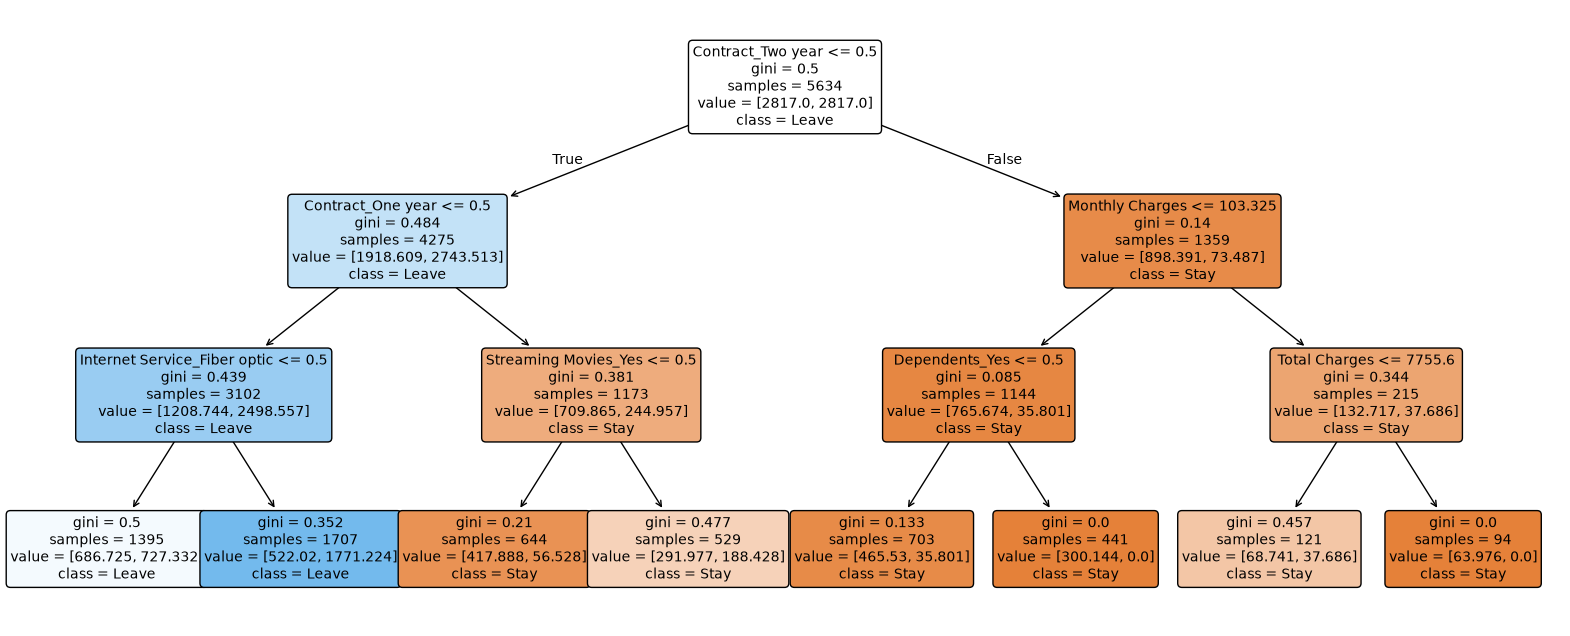

In [123]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

small_tree = DecisionTreeClassifier(max_depth=3, class_weight='balanced', random_state=42)
small_tree.fit(X_train, y_train)

plt.figure(figsize=(20, 8))
plot_tree(
    small_tree,
    feature_names=X_train.columns,
    class_names=['Stay', 'Leave'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.show()

## 26. Best Parameters of the Final Model

In [124]:
Grid_search_Class_wight['XGB'].best_params_

{'model__colsample_bytree': 0.8,
 'model__learning_rate': 0.1,
 'model__max_depth': 3,
 'model__min_child_weight': 5,
 'model__n_estimators': 100,
 'model__reg_lambda': 1,
 'model__subsample': 1.0}

## Conclusion

**Final model:** XGBoost with `scale_pos_weight` (class weights)

**Best parameters:** `colsample_bytree=0.8`, `learning_rate=0.1`, `max_depth=3`, `min_child_weight=5`, `n_estimators=100`, `reg_lambda=1`, `subsample=1.0`

**Model selection (CV F1):**

| Model | F1 Train | CV F1 |
|---|---|---|
| Random Forest (class_weight) | 0.747 | 0.654 |
| XGBoost (class_weight) | 0.672 | 0.653 |
| Random Forest (SMOTENC) | 0.695 | 0.653 |
| Soft Voting | – | 0.654 |
| Hard Voting | – | 0.656 |

All top results are within ~0.003, which is smaller than the variation between CV folds, so they are effectively tied. XGBoost was chosen as the simplest model with the least overfitting.

**Test set results:**

| Class | Precision | Recall | F1 |
|---|---|---|---|
| Stay (0) | 0.92 | 0.73 | 0.81 |
| Leave (1) | 0.52 | 0.81 | 0.63 |

- The model catches **81%** of churning customers (304 of 374).
- About half of the customers flagged as churners actually leave.

**Most important features:** Contract type (one / two year), Internet Service (Fiber optic / No), Payment Method (Electronic check), Dependents, Tenure Months.

**SMOTENC vs class_weight:** similar F1, but class weights gave higher recall for most models and are simpler (no synthetic data).